<a href="https://colab.research.google.com/github/jesuscarpio5/Analisis-deportivo/blob/main/02_informe_equipo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install mplsoccer statsbombpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [mplsoccer]


In [2]:
from statsbombpy import sb
import pandas as pd
import warnings
warnings.filterwarnings("ignore")

EQUIPO = "France"
partidos = sb.matches(competition_id=43, season_id=3)
partidos_eq = partidos[(partidos.home_team == EQUIPO) | (partidos.away_team == EQUIPO)]

eventos = pd.concat([sb.events(match_id=m) for m in partidos_eq.match_id], ignore_index=True)
eventos = eventos[eventos.team == EQUIPO]
print(len(partidos_eq), "partidos,", len(eventos), "eventos")

7 partidos, 12083 eventos


In [3]:
import numpy as np

pases = eventos[(eventos.type == "Pass") & (eventos.pass_outcome.isna())].copy()
pases[["x","y"]] = pd.DataFrame(pases.location.tolist(), index=pases.index)
pases[["x2","y2"]] = pd.DataFrame(pases.pass_end_location.tolist(), index=pases.index)

dist_ini = np.sqrt((120 - pases.x)**2 + (40 - pases.y)**2)
dist_fin = np.sqrt((120 - pases.x2)**2 + (40 - pases.y2)**2)
progresivos = pases[(dist_fin < 0.75 * dist_ini) & (pases.x2 > pases.x)]
print(len(progresivos), "pases progresivos de", len(pases))

263 pases progresivos de 2600


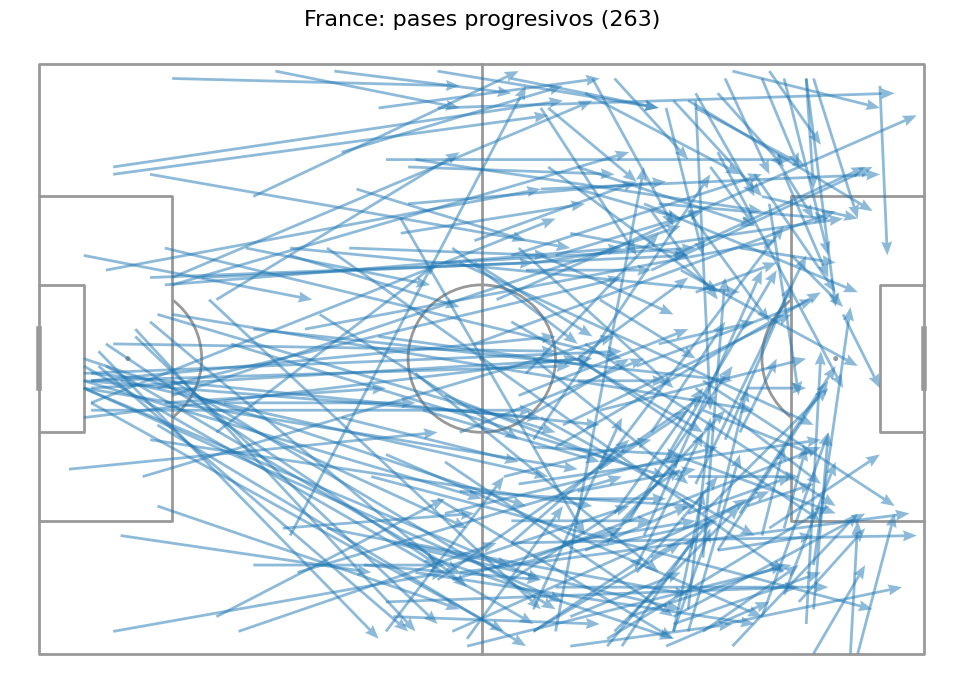

In [4]:
import matplotlib.pyplot as plt
from mplsoccer import Pitch

pitch = Pitch(pitch_type="statsbomb", line_color="#999999")
fig, ax = pitch.draw(figsize=(10, 7))

pitch.arrows(progresivos.x, progresivos.y, progresivos.x2, progresivos.y2,
             ax=ax, width=2, headwidth=4, color="#1f77b4", alpha=0.5)
# si cambio equipo por el nombre de un equipo podemos ver cualquier equipo
ax.set_title(f"{EQUIPO}: pases progresivos ({len(progresivos)})", fontsize=16)
plt.show()

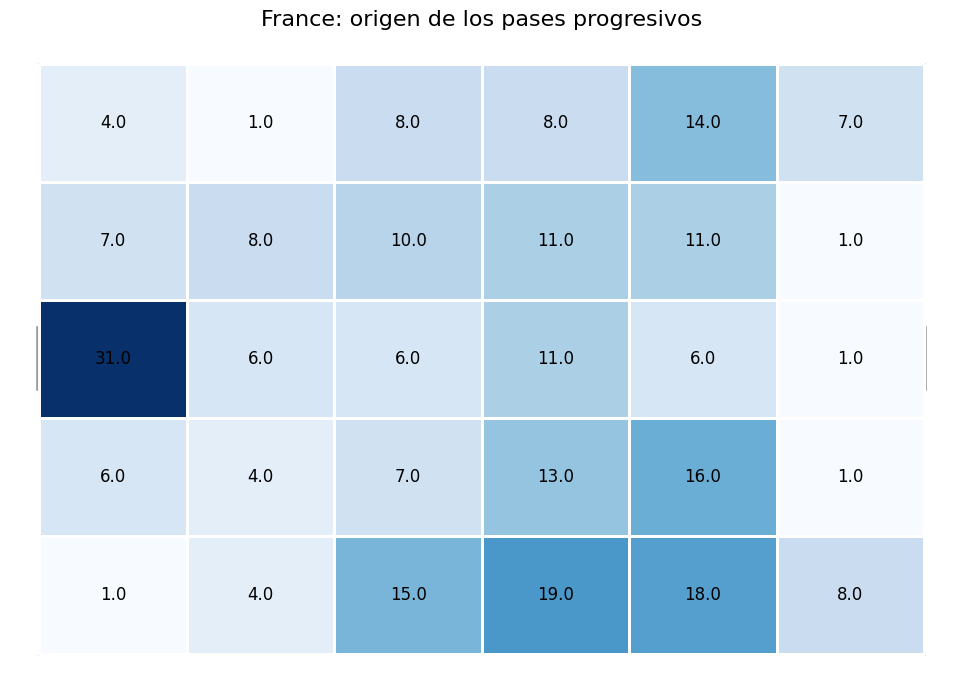

In [5]:
pitch = Pitch(pitch_type="statsbomb", line_color="#999999")
fig, ax = pitch.draw(figsize=(10, 7))

bin_stat = pitch.bin_statistic(progresivos.x, progresivos.y, statistic="count", bins=(6, 5))
pitch.heatmap(bin_stat, ax=ax, cmap="Blues", edgecolor="white")
pitch.label_heatmap(bin_stat, ax=ax, color="black", fontsize=12, ha="center", va="center")

ax.set_title(f"{EQUIPO}: origen de los pases progresivos", fontsize=16)
plt.show()

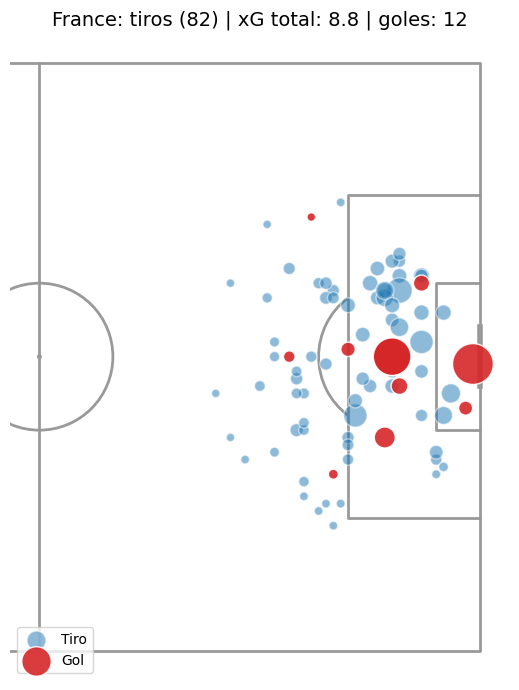

In [6]:
tiros = eventos[eventos.type == "Shot"].copy()
tiros[["x","y"]] = pd.DataFrame(tiros.location.tolist(), index=tiros.index)

pitch = Pitch(pitch_type="statsbomb", line_color="#999999", half=True)
fig, ax = pitch.draw(figsize=(9, 7))

goles = tiros[tiros.shot_outcome == "Goal"]
otros = tiros[tiros.shot_outcome != "Goal"]

pitch.scatter(otros.x, otros.y, s=otros.shot_statsbomb_xg * 900 + 30,
              ax=ax, color="#1f77b4", alpha=0.5, edgecolors="white", label="Tiro")
pitch.scatter(goles.x, goles.y, s=goles.shot_statsbomb_xg * 900 + 30,
              ax=ax, color="#d62728", alpha=0.9, edgecolors="white", label="Gol")

ax.legend(loc="lower left")
ax.set_title(f"{EQUIPO}: tiros ({len(tiros)}) | xG total: {tiros.shot_statsbomb_xg.sum():.1f} | goles: {len(goles)}", fontsize=14)
plt.show()

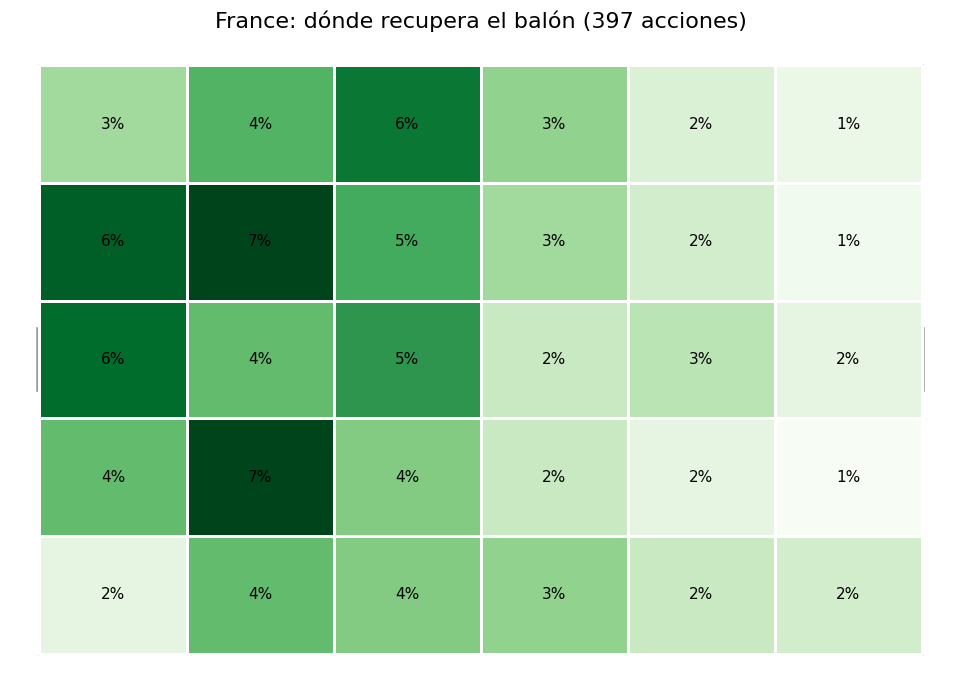

In [7]:
recup = eventos[eventos.type.isin(["Ball Recovery", "Interception"])].copy()
recup[["x","y"]] = pd.DataFrame(recup.location.tolist(), index=recup.index)

pitch = Pitch(pitch_type="statsbomb", line_color="#999999")
fig, ax = pitch.draw(figsize=(10, 7))

bin_stat = pitch.bin_statistic(recup.x, recup.y, statistic="count", bins=(6, 5), normalize=True)
pitch.heatmap(bin_stat, ax=ax, cmap="Greens", edgecolor="white")
pitch.label_heatmap(bin_stat, ax=ax, str_format="{:.0%}", color="black", fontsize=11, ha="center", va="center")

ax.set_title(f"{EQUIPO}: dónde recupera el balón ({len(recup)} acciones)", fontsize=16)
plt.show()

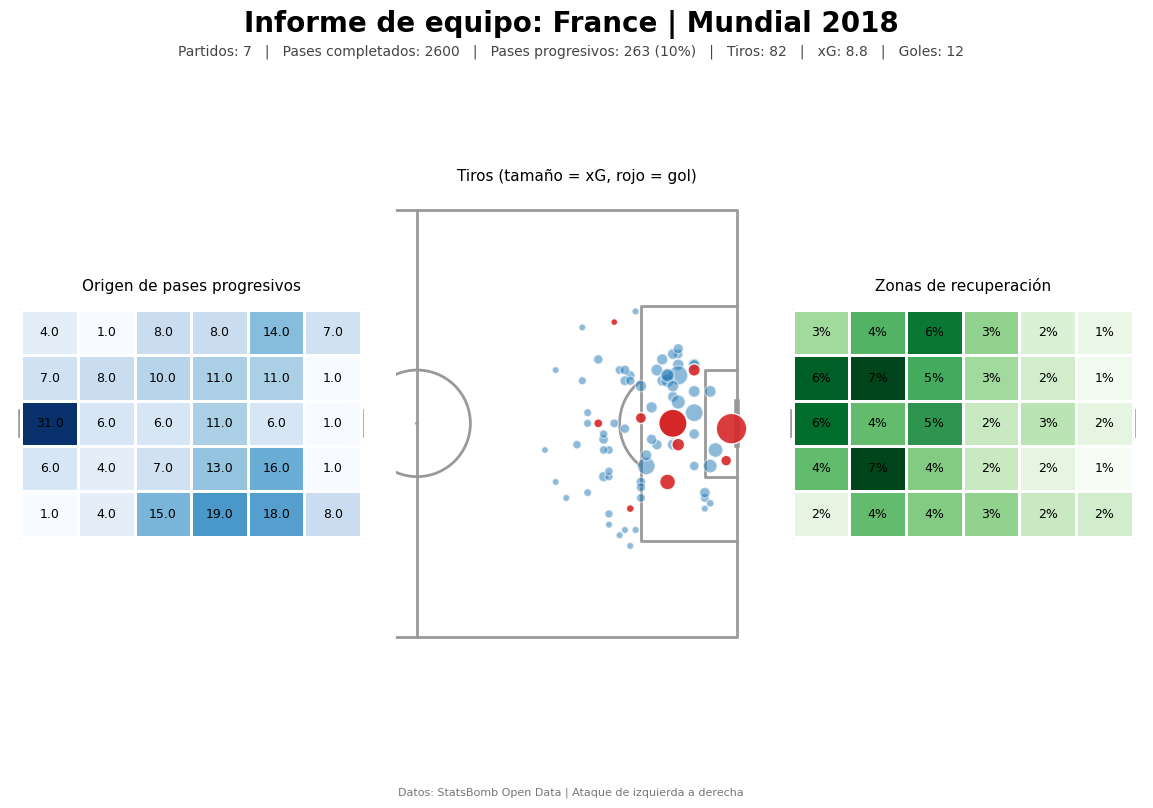

In [8]:
import matplotlib.pyplot as plt
from mplsoccer import Pitch

# Datos clave
n_partidos = len(partidos_eq)
n_pases = len(pases)
pct_prog = len(progresivos) / n_pases * 100
n_tiros = len(tiros)
xg_total = tiros.shot_statsbomb_xg.sum()
n_goles = (tiros.shot_outcome == "Goal").sum()
n_recup = len(recup)

fig = plt.figure(figsize=(11.69, 8.27))  # tamaño A4 horizontal
fig.suptitle(f"Informe de equipo: {EQUIPO} | Mundial 2018", fontsize=20, fontweight="bold", y=0.97)

# Resumen de datos clave
resumen = (f"Partidos: {n_partidos}   |   Pases completados: {n_pases}   |   "
           f"Pases progresivos: {len(progresivos)} ({pct_prog:.0f}%)   |   "
           f"Tiros: {n_tiros}   |   xG: {xg_total:.1f}   |   Goles: {n_goles}")
fig.text(0.5, 0.915, resumen, ha="center", fontsize=10, color="#444444")

# Tres paneles
ax1 = fig.add_axes([0.02, 0.08, 0.31, 0.78])
ax2 = fig.add_axes([0.35, 0.08, 0.31, 0.78])
ax3 = fig.add_axes([0.68, 0.08, 0.31, 0.78])

# 1) Pases progresivos (origen)
p1 = Pitch(pitch_type="statsbomb", line_color="#999999")
p1.draw(ax=ax1)
b1 = p1.bin_statistic(progresivos.x, progresivos.y, statistic="count", bins=(6, 5))
p1.heatmap(b1, ax=ax1, cmap="Blues", edgecolor="white")
p1.label_heatmap(b1, ax=ax1, color="black", fontsize=9, ha="center", va="center")
ax1.set_title("Origen de pases progresivos", fontsize=11)

# 2) Tiros con xG
p2 = Pitch(pitch_type="statsbomb", line_color="#999999", half=True)
p2.draw(ax=ax2)
goles = tiros[tiros.shot_outcome == "Goal"]
otros = tiros[tiros.shot_outcome != "Goal"]
p2.scatter(otros.x, otros.y, s=otros.shot_statsbomb_xg * 500 + 20, ax=ax2,
           color="#1f77b4", alpha=0.5, edgecolors="white")
p2.scatter(goles.x, goles.y, s=goles.shot_statsbomb_xg * 500 + 20, ax=ax2,
           color="#d62728", alpha=0.9, edgecolors="white")
ax2.set_title("Tiros (tamaño = xG, rojo = gol)", fontsize=11)

# 3) Recuperaciones
p3 = Pitch(pitch_type="statsbomb", line_color="#999999")
p3.draw(ax=ax3)
b3 = p3.bin_statistic(recup.x, recup.y, statistic="count", bins=(6, 5), normalize=True)
p3.heatmap(b3, ax=ax3, cmap="Greens", edgecolor="white")
p3.label_heatmap(b3, ax=ax3, str_format="{:.0%}", color="black", fontsize=9, ha="center", va="center")
ax3.set_title("Zonas de recuperación", fontsize=11)

fig.text(0.5, 0.02, "Datos: StatsBomb Open Data | Ataque de izquierda a derecha",
         ha="center", fontsize=8, color="#777777")

fig.savefig("informe_equipo.pdf")
fig.savefig("informe_equipo.png", dpi=200)
plt.show()